# 01 — Simulation, corruption and exploratory analysis

This notebook generates every trajectory used in the study.

* **Systems.** Lorenz-63 $(\sigma,\rho,\beta)=(10,28,8/3)$; the four-species competitive Lotka–Volterra model of Vano et al. (2006), $\dot x_i = r_i x_i\,(1-\sum_j a_{ij}x_j)$; and the classical predator–prey model as a non-chaotic control.
* **Integration.** `scipy.integrate.solve_ivp` with DOP853 at $\mathrm{rtol}=10^{-10}$, $\mathrm{atol}=10^{-12}$.
* **Corruption.** Sub-sampling at $\Delta t_{\mathrm{obs}} = r\,t_{\mathrm{char}}$, $r\in\{1/75, 1/15, 2/15, 4/15\}$, and additive Gaussian noise $\eta\sim\mathcal N(0,(\varepsilon\,\mathrm{std}\,x)^2)$, $\varepsilon\in\{0,1,2,5,10,20\}\%$.

Time is expressed in units of a characteristic period $t_{\mathrm{char}}$ (mean interval between maxima of the oscillating coordinate). Both chaotic systems have $\lambda_{\max} t_{\mathrm{char}}\approx 0.7$, so one grid in $t_{\mathrm{char}}$ samples both at comparable resolution relative to their predictability horizon.

In [1]:
import sys, os, json
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

from src.systems import get_system, simulate
from src.library import PolyLibrary
from src import experiment as E
from src import metrics as M
from src import plotting as P

P.setup()
np.set_printoptions(precision=4, suppress=True)

## 1. Ground-truth models in the degree-2 monomial library

In [2]:
for name in ["lorenz", "lv4", "lv2"]:
    s = E.get_sys(name)
    lib = PolyLibrary(s.d, 2, s.symbols)
    nnz = np.count_nonzero(s.Xi_true)
    print(f"--- {name}: d = {s.d}, library size p = {lib.n_terms}, active terms {nnz}/{s.Xi_true.size}")
    print(lib.pretty(s.Xi_true, s.symbols))

--- lorenz: d = 3, library size p = 10, active terms 7/30
dx/dt = -10.000 x +10.000 y
dy/dt = +28.000 x -1.000 y -1.000 x z
dz/dt = -2.667 z +1.000 x y
--- lv4: d = 4, library size p = 15, active terms 17/60
dx_1/dt = +1.000 x_1 -1.000 x_1^2 -1.090 x_1 x_2 -1.520 x_1 x_3
dx_2/dt = +0.720 x_2 -0.720 x_2^2 -0.317 x_2 x_3 -0.979 x_2 x_4
dx_3/dt = +1.530 x_3 -3.565 x_1 x_3 -1.530 x_3^2 -0.719 x_3 x_4
dx_4/dt = +1.270 x_4 -1.537 x_1 x_4 -0.648 x_2 x_4 -0.444 x_3 x_4 -1.270 x_4^2
--- lv2: d = 2, library size p = 6, active terms 4/12
du/dt = +0.667 u -1.333 u v
dv/dt = -1.000 v +1.000 u v


## 2. Reference orbits, characteristic periods and Lyapunov exponents

Each reference orbit starts after a burn-in of $100\,t_{\mathrm{char}}$ and covers $200\,t_{\mathrm{char}}$. The largest Lyapunov exponent is re-estimated with the Benettin two-trajectory method on the exact vector field and the RK4 step $h=t_{\mathrm{char}}/75$ used for every learned model; this checks that the integrator itself does not distort the invariant dynamics.

In [3]:
summary = {}
for name in ["lorenz", "lv4", "lv2"]:
    s = E.get_sys(name)
    ref = E.reference(name)
    X, h = ref["X_ref"], float(ref["h"])
    # characteristic period: mean spacing of prominent maxima of the last coordinate
    # (z for Lorenz), or of the first coordinate otherwise
    c = X[:, 2] if name == "lorenz" else X[:, 0]
    pk, _ = find_peaks(c, prominence=0.1 * c.std())
    t_peak = float(np.mean(np.diff(pk)) * h)
    lam = M.lyapunov_benettin(s.rhs_batch, X[0], h, int(round(150 * s.t_char / h)), transient=10) if s.lyap > 0 else 0.0
    summary[name] = dict(t_char_used=s.t_char, t_char_peaks=t_peak, lyap_literature=s.lyap,
                         lyap_benettin=float(lam), lyap_x_tchar=float(lam * s.t_char),
                         std=ref["std"].tolist(), n_ref=len(X))
    print(f"{name:7s} t_char(peaks) = {t_peak:7.3f}  (used {s.t_char})   lambda_max = {lam:.4f} "
          f"(literature {s.lyap})   lambda * t_char = {lam * s.t_char:.3f}")
os.makedirs("../results/metrics", exist_ok=True)
json.dump(summary, open("../results/metrics/system_summary.json", "w"), indent=2)

lorenz  t_char(peaks) =   0.753  (used 0.75)   lambda_max = 0.9057 (literature 0.9056)   lambda * t_char = 0.679


lv4     t_char(peaks) =  33.713  (used 35.0)   lambda_max = 0.0191 (literature 0.0203)   lambda * t_char = 0.668
lv2     t_char(peaks) =   8.272  (used 8.0)   lambda_max = 0.0000 (literature 0.0)   lambda * t_char = 0.000


## 3. Phase-space portraits

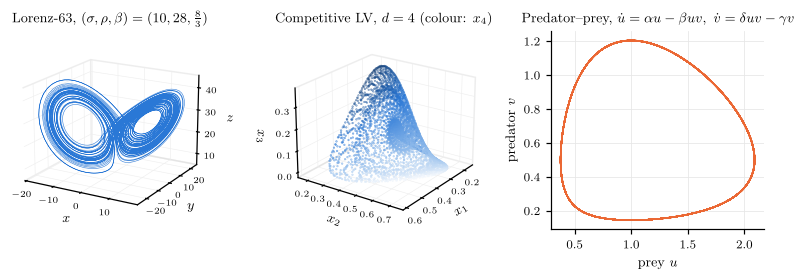

In [4]:
fig = plt.figure(figsize=(7.2, 2.6))
ref = E.reference("lorenz"); X = ref["X_ref"][:6000]
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.plot(X[:, 0], X[:, 1], X[:, 2], lw=0.35, color=P.COLORS["C1-OLS"])
ax.set_xlabel(r"$x$", labelpad=-8); ax.set_ylabel(r"$y$", labelpad=-8); ax.set_zlabel(r"$z$", labelpad=-8)
ax.set_title(r"Lorenz-63, $(\sigma,\rho,\beta)=(10,28,\tfrac{8}{3})$")
ax.tick_params(pad=-3, labelsize=6); P.clean_3d(ax); ax.view_init(18, -60)

ref = E.reference("lv4"); X = ref["X_ref"][:12000]
ax = fig.add_subplot(1, 3, 2, projection="3d")
sc = ax.scatter(X[::3, 0], X[::3, 1], X[::3, 2], c=X[::3, 3], s=0.15, cmap=P.SEQ, rasterized=True)
ax.set_xlabel(r"$x_1$", labelpad=-8); ax.set_ylabel(r"$x_2$", labelpad=-8); ax.set_zlabel(r"$x_3$", labelpad=-8)
ax.set_title(r"Competitive LV, $d=4$ (colour: $x_4$)")
ax.tick_params(pad=-3, labelsize=6); P.clean_3d(ax); ax.view_init(22, 35)

ref = E.reference("lv2"); X = ref["X_ref"][:2000]
ax = fig.add_subplot(1, 3, 3)
ax.plot(X[:, 0], X[:, 1], color=P.COLORS["C2-SINDy-SG"], lw=0.9)
ax.set_xlabel(r"prey $u$"); ax.set_ylabel(r"predator $v$")
ax.set_title(r"Predator--prey, $\dot u=\alpha u-\beta uv,\ \dot v=\delta uv-\gamma v$")
fig.tight_layout()
P.save(fig, "fig01_attractors")
plt.show()

In [5]:
# larger stand-alone renders of the two chaotic attractors (README / poster)
for name, cols, lab in [("lorenz", (0, 1, 2), (r"$x$", r"$y$", r"$z$")),
                        ("lv4", (0, 1, 2), (r"$x_1$", r"$x_2$", r"$x_3$"))]:
    ref = E.reference(name); X = ref["X_ref"][:10000]
    fig = plt.figure(figsize=(3.6, 3.4))
    ax = fig.add_subplot(projection="3d")
    t = np.linspace(0, 1, len(X))
    for k in range(0, len(X) - 1, 25):
        ax.plot(X[k:k + 26, cols[0]], X[k:k + 26, cols[1]], X[k:k + 26, cols[2]],
                color=P.SEQ(0.35 + 0.65 * t[k]), lw=0.45)
    ax.set_xlabel(lab[0], labelpad=-6); ax.set_ylabel(lab[1], labelpad=-6); ax.set_zlabel(lab[2], labelpad=-6)
    ax.tick_params(pad=-2, labelsize=6); P.clean_3d(ax)
    ax.view_init(18, -60 if name == "lorenz" else 35)
    P.save(fig, f"fig01_attractor_{name}")
    plt.close(fig)
print("saved")

saved


## 4. Sparse and noisy observation records

A training record has total length $T=\tfrac{80}{3}\,t_{\mathrm{char}}$ (20 time units for Lorenz) and is made of four independent experiments. Each starts from a random point of the attractor displaced by $0.5$ standard deviations per coordinate; the last 20% of every experiment is held out for model selection.

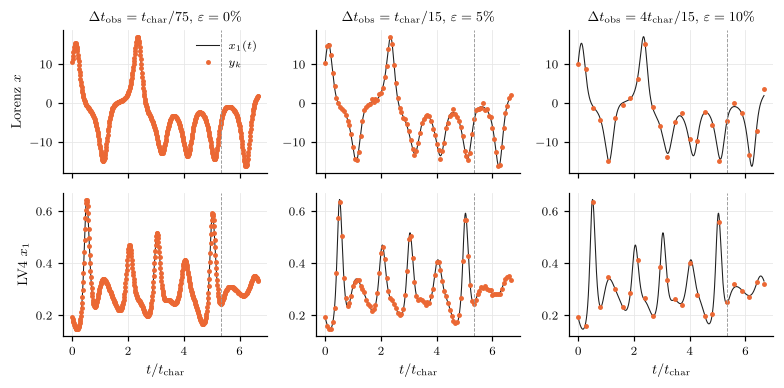

In [6]:
ds_examples = {}
fig, axes = plt.subplots(2, 3, figsize=(7.2, 3.6), sharex="col")
cases = [(1/75, 0.0), (1/15, 0.05), (4/15, 0.10)]
for j, (r, eps) in enumerate(cases):
    for i, name in enumerate(["lorenz", "lv4"]):
        s = E.get_sys(name)
        ds = E.make_dataset(name, r, eps, seed=0)
        g = ds["segs"][0]
        t_f, X_f = simulate(s, g["x0"], g["t"][-1], s.t_char / 750)
        ax = axes[i, j]
        ax.plot(t_f / s.t_char, X_f[:, 0], color=P.COLORS["truth"], lw=0.7, label=r"$x_1(t)$")
        ax.plot(g["t"] / s.t_char, g["Y"][:, 0], "o", ms=2.2, color=P.COLORS["C2-SINDy-SG"], label=r"$y_k$")
        ax.axvline(g["t"][g["n_fit"]] / s.t_char, color="#999999", lw=0.6, ls="--")
        if i == 0:
            frac = {1/75: r"t_{\rm char}/75", 1/15: r"t_{\rm char}/15", 4/15: r"4t_{\rm char}/15"}[r]
            ax.set_title(rf"$\Delta t_{{\rm obs}}={frac}$, $\varepsilon={int(eps*100)}\%$")
        if i == 1:
            ax.set_xlabel(r"$t/t_{\rm char}$")
        if j == 0:
            ax.set_ylabel(r"Lorenz $x$" if name == "lorenz" else r"LV4 $x_1$")
        ds_examples[(name, r, eps)] = ds
axes[0, 0].legend(loc="upper right", frameon=False)
fig.tight_layout()
P.save(fig, "fig01_corruption")
plt.show()

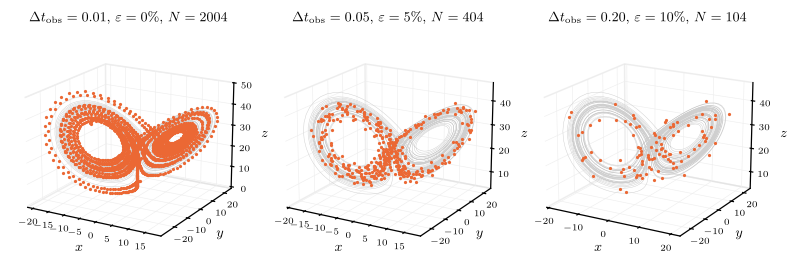

In [7]:
# the same records in phase space: what the algorithms actually see
fig = plt.figure(figsize=(7.2, 2.5))
for j, (r, eps) in enumerate(cases):
    ds = ds_examples[("lorenz", r, eps)]
    ref = E.reference("lorenz")
    ax = fig.add_subplot(1, 3, j + 1, projection="3d")
    Xr = ref["X_ref"][:5000]
    ax.plot(Xr[:, 0], Xr[:, 1], Xr[:, 2], color="#cfcfcf", lw=0.3)
    for g in ds["segs"]:
        ax.scatter(g["Y"][:, 0], g["Y"][:, 1], g["Y"][:, 2], s=1.2, color=P.COLORS["C2-SINDy-SG"], depthshade=False)
    ax.set_title(rf"$\Delta t_{{\rm obs}}={r*0.75:.2f}$, $\varepsilon={int(eps*100)}\%$, $N={sum(len(g['t']) for g in ds['segs'])}$")
    ax.tick_params(pad=-3, labelsize=6); P.clean_3d(ax); ax.view_init(18, -60)
    ax.set_xlabel(r"$x$", labelpad=-8); ax.set_ylabel(r"$y$", labelpad=-8); ax.set_zlabel(r"$z$", labelpad=-8)
fig.tight_layout()
P.save(fig, "fig01_samples_phase_space")
plt.show()

## 5. Identifiability: conditioning of the library on the data

Equation recovery is a regression on $\Theta(X)\in\mathbb R^{N\times p}$. Its smallest singular value bounds how much measurement error is amplified into the coefficients, $\|\delta\Xi\|\lesssim \|\delta\dot X\|/\sigma_{\min}(\Theta)$. A trajectory confined to a thin attractor makes some monomials nearly collinear. We compare a single orbit on the attractor with the four-experiment design, at equal record length.

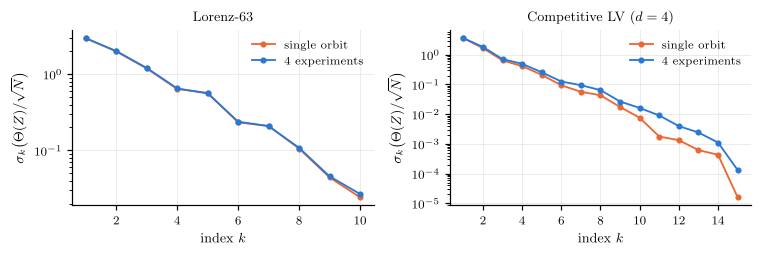

,system,design,sigma_min,cond
0,lorenz,single orbit,0.024389,125.432365
1,lorenz,4 experiments,0.026931,115.604639
2,lv4,single orbit,0.000016,226532.122688
3,lv4,4 experiments,0.000133,33681.655219


In [8]:
rows = []
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.4))
for ax, name in zip(axes, ["lorenz", "lv4"]):
    s = E.get_sys(name); lib = PolyLibrary(s.d)
    for design, kw, col in [("single orbit", dict(n_exp=1, pert=0.0), P.COLORS["C2-SINDy-SG"]),
                            ("4 experiments", dict(n_exp=4, pert=0.5), P.COLORS["C1-OLS"])]:
        svs = []
        for seed in range(5):
            ds = E.make_dataset(name, 1/75, 0.0, seed, **kw)
            X = np.concatenate([g["X"] for g in ds["segs"]])
            rms = np.sqrt(np.mean(X ** 2, axis=0))
            sv = np.linalg.svd(lib(X / rms) / np.sqrt(len(X)), compute_uv=False)
            svs.append(sv)
        svs = np.array(svs)
        ax.semilogy(np.arange(1, lib.n_terms + 1), svs.mean(0), "o-", ms=3, color=col, label=design)
        rows.append(dict(system=name, design=design, sigma_min=svs[:, -1].mean(), cond=(svs[:, 0] / svs[:, -1]).mean()))
    ax.set_xlabel(r"index $k$"); ax.set_ylabel(r"$\sigma_k\big(\Theta(Z)/\sqrt{N}\big)$")
    ax.set_title("Lorenz-63" if name == "lorenz" else "Competitive LV ($d=4$)")
    ax.legend(frameon=False)
fig.tight_layout()
P.save(fig, "fig01_library_spectrum")
plt.show()
import pandas as pd
cond_tab = pd.DataFrame(rows)
cond_tab.to_csv("../results/metrics/library_conditioning.csv", index=False)
cond_tab

## 6. Archive the corrupted datasets (seed 0) for inspection

In [9]:
arch = {}
for name in ["lorenz", "lv4"]:
    for r in E.DT_RATIOS:
        for eps in E.NOISES:
            ds = E.make_dataset(name, r, eps, 0)
            for k, g in enumerate(ds["segs"]):
                key = f"{name}_dt{r:.4f}_n{eps:.2f}_e{k}"
                arch[key + "_t"] = g["t"]; arch[key + "_y"] = g["Y"]; arch[key + "_x"] = g["X"]
np.savez_compressed("../data/datasets_seed0.npz", **arch)
print(len(arch) // 3, "experiment records written to data/datasets_seed0.npz")

192 experiment records written to data/datasets_seed0.npz
